# Buổi G4: Tạo cột mới, giúp mô hình đơn giản bắt được quan hệ phức tạp

**Hiện trường.** Chị Hạnh dùng hồi quy tuyến tính (B1, B3) để đoán tiền thuê mặt bằng và lượng khách theo giờ. Mô hình chạy được nhưng hay sai theo kiểu có quy luật: nhà rộng thì đoán thấp, giờ cao điểm thì đoán lệch. Chị nghi dữ liệu có quan hệ **cong** mà đường thẳng không bắt được.

Có hai hướng: đổi sang mô hình phức tạp hơn (mạng nơ-ron, rừng), hoặc **tạo cột mới** từ cột cũ sao cho mô hình đơn giản vẫn bắt được. Buổi này dạy hướng thứ hai, gọi là **thiết kế cột** (*feature engineering*): bình phương, tích hai cột, chia khoảng, đổi giờ thành sin và cos, lấy log.

**Ẩn dụ:** muốn đo độ rộng của miếng đất hình chữ nhật, thước đo chiều dài và chiều rộng riêng lẻ thì chưa đủ; **nhân hai số lại** mới ra diện tích. Cột mới là phép nhân đó: ta đưa cho mô hình thứ mà nó không tự nghĩ ra được.

**Mindset của người làm dữ liệu:** cột mới có giá trị khi nó dựa trên **hiểu biết về bài toán** (diện tích là dài nhân rộng; giờ 23 và giờ 0 là liền nhau). Mọi cột mới phải được kiểm bằng kiểm định chéo (D1), không chỉ bằng niềm tin.

**Lưu ý:** dữ liệu dựng có chủ đích để biết quy luật thật; dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: thêm cột bình phương, đường thẳng thành đường cong |
| Chặng 1 | Tích hai cột: tương tác |
| Chặng 2 | Chia khoảng: khi ảnh hưởng không đều |
| Chặng 3 | Giờ trong ngày: sin và cos |
| Chặng 4 | Số lệch: lấy log |
| Chặng 5 | Bẫy: thêm quá nhiều cột mới |

## Chặng 0: Thấy ngay, thêm cột bình phương

**Câu hỏi:** tiền thuê tăng theo diện tích kiểu cong; đường thẳng sai đến đâu, và một cột mới cứu được không?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

R2, area only: 0.916 | area + area^2: 0.96


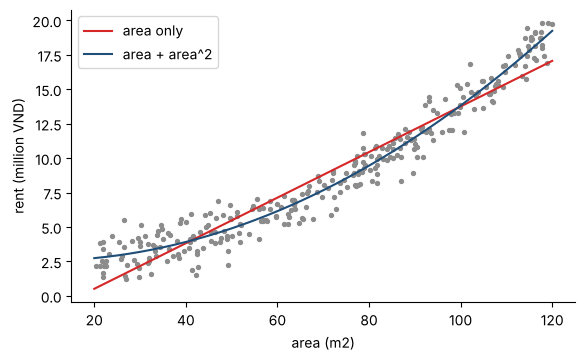

In [2]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
rng = np.random.RandomState(0)
area = rng.uniform(20, 120, 300)
rent = 2 + 0.0012 * area ** 2 + rng.normal(0, 1.0, 300)
df0 = pd.DataFrame({"area": area, "rent": rent})
kf = KFold(5, shuffle=True, random_state=0)
lin = LinearRegression()
r2_lin = cross_val_score(lin, df0[["area"]], df0["rent"], cv=kf, scoring="r2").mean()
df0["area_sq"] = df0["area"] ** 2
r2_sq = cross_val_score(lin, df0[["area", "area_sq"]], df0["rent"], cv=kf, scoring="r2").mean()
print("R2, area only:", round(r2_lin, 3), "| area + area^2:", round(r2_sq, 3))
fit1 = LinearRegression().fit(df0[["area"]], df0["rent"]); fit2 = LinearRegression().fit(df0[["area", "area_sq"]], df0["rent"])
xs = np.linspace(20, 120, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(df0["area"], df0["rent"], s=8, color=GRAY)
ax.plot(xs, fit1.predict(pd.DataFrame({"area": xs})), color="tab:red", label="area only")
ax.plot(xs, fit2.predict(pd.DataFrame({"area": xs, "area_sq": xs ** 2})), color=BLUE, label="area + area^2")
ax.set_xlabel("area (m2)"); ax.set_ylabel("rent (million VND)"); ax.legend(); plt.show()

**Giải thích từng dòng**

- `rent = 2 + 0.0012 * area ** 2 + noise`: quy luật thật: tiền thuê tăng theo **bình phương** diện tích (nhà rộng đắt dần lên). Dữ liệu dựng có chủ đích.
- `df0["area"] ** 2`: **cột mới**: bình phương diện tích. Mô hình vẫn là tuyến tính (cộng các cột nhân hệ số), nhưng cột mới cho nó quyền uốn cong.
- `cross_val_score(lin, ..., scoring="r2")`: đo R² bằng kiểm định chéo (D1) để so công bằng.

**Cách đọc.**
- **Con số:** R² chỉ với diện tích **0,916**; thêm cột bình phương **0,960**.
- **Bức tranh:** đường đỏ (thẳng) lệch ở hai đầu, cong ở giữa; đường xanh bám theo quy luật cong. Mô hình **vẫn là hồi quy tuyến tính**: "tuyến tính" nói về cách các hệ số cộng lại, không nói cột phải thẳng.
- **Câu hỏi tiếp:** nếu có hai cột và chúng tác động **cùng nhau** thì sao?

**Mang về chặng 1:** thêm cột bình phương cho hồi quy tuyến tính quyền uốn cong.

## Chặng 1: Tích hai cột, tương tác

**Câu hỏi:** giá thuê phụ thuộc diện tích **nhân** số phòng, mô hình cộng đơn giản có bắt được?

In [3]:
n = 400
rooms = rng.randint(1, 6, n)
area2 = rng.uniform(25, 100, n)
rent2 = 1 + 0.03 * area2 * rooms + rng.normal(0, 1.0, n)
df1 = pd.DataFrame({"area": area2, "rooms": rooms})
r2_add = cross_val_score(LinearRegression(), df1, rent2, cv=kf, scoring="r2").mean()
df1_x = df1.assign(area_x_rooms=df1["area"] * df1["rooms"])
r2_x = cross_val_score(LinearRegression(), df1_x, rent2, cv=kf, scoring="r2").mean()
poly_inter = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False).fit(df1)
print("columns made by PolynomialFeatures(interaction_only):", list(poly_inter.get_feature_names_out()))
print("R2, additive:", round(r2_add, 3), "| with area*rooms:", round(r2_x, 3))

columns made by PolynomialFeatures(interaction_only): ['area', 'rooms', 'area rooms']
R2, additive: 0.846 | with area*rooms: 0.924


**Giải thích từng dòng**

- `rent2 = 1 + 0.03 * area2 * rooms`: quy luật thật: mỗi mét vuông đắt thêm theo số phòng, tức tiền thuê phụ thuộc **tích** hai cột.
- `df1["area"] * df1["rooms"]`: cột tương tác: tích hai cột.
- `PolynomialFeatures(degree=2, interaction_only=True)`: công cụ tự sinh các tích đôi một. `interaction_only=True` chỉ lấy tích giữa hai cột khác nhau, không lấy bình phương.
- `get_feature_names_out()`: tên các cột sinh ra, để ta đọc được.

**Cách đọc.**
- **Con số:** R² của mô hình cộng **0,846**, thêm tích diện tích nhân số phòng **0,924**.
- **Bức tranh:** mô hình cộng cho rằng thêm một phòng luôn cộng một khoản cố định; thực tế khoản đó **lớn dần theo diện tích**. Tích hai cột cho mô hình biết điều này. `PolynomialFeatures` sinh sẵn các cột `['area', 'rooms', 'area rooms']`.
- **Quy tắc đọc:** tương tác đáng thử khi bạn có lý do hiểu bài toán ("hai thứ này nhân lên nhau"); rừng và mạng nơ-ron tự học tương tác, mô hình tuyến tính thì phải **đưa cho nó**.

**Mang về chặng 2:** tích hai cột cho mô hình tuyến tính khả năng bắt tác động chung.

## Chặng 2: Chia khoảng

**Câu hỏi:** chi tiêu theo tuổi không tăng đều (trẻ và già chi nhiều, trung niên ít), đường thẳng làm gì?

In [4]:
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder
age = rng.uniform(18, 80, 500)
spend = 10 + 0.012 * (age - 45) ** 2 + rng.normal(0, 1.2, 500)
df2 = pd.DataFrame({"age": age})
candidates = {
    "linear age": make_pipeline(LinearRegression()),
    "age + age^2": make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()),
    "age bins (8, one-hot)": make_pipeline(KBinsDiscretizer(n_bins=8, encode="onehot", strategy="quantile"), LinearRegression()),
}
bin_table = pd.Series({name: cross_val_score(m, df2, spend, cv=kf, scoring="r2").mean() for name, m in candidates.items()}).round(3)
print(bin_table.to_string())
edges = KBinsDiscretizer(n_bins=8, encode="ordinal", strategy="quantile").fit(df2).bin_edges_[0].round(0)
print("bin edges (age):", edges)

linear age               0.231
age + age^2              0.910
age bins (8, one-hot)    0.856
bin edges (age): [18. 27. 34. 42. 50. 58. 65. 73. 80.]


**Giải thích từng dòng**

- `spend = 10 + 0.012 * (age - 45) ** 2`: quy luật thật: dạng chữ U, thấp nhất quanh tuổi 45.
- `KBinsDiscretizer(n_bins=8, encode="onehot", strategy="quantile")`: chia tuổi thành 8 khoảng có số người gần bằng nhau (`quantile`), rồi mỗi khoảng thành một cột 0 hoặc 1 (như cột chữ ở B4). Mô hình học **một mức riêng cho từng khoảng**.
- `bin_edges_[0]`: các mốc chia tuổi.

**Cách đọc.**
- **Con số:** R² của đường thẳng **0,231**, thêm bình phương **0,910**, chia 8 khoảng **0,856**. Các mốc chia tuổi: **[18, 27, 34, 42, 50, 58, 65, 73, 80]**.
- **Bức tranh:** đường thẳng không thể mô tả hình chữ U. Chia khoảng không cần biết hình dạng trước (chữ U, bậc thang, bất kỳ): mỗi khoảng tự có mức riêng. Với dữ liệu mà ta **biết** quy luật là bậc hai, thêm bình phương gọn hơn và thường ngang hoặc hơn.
- **Quy tắc đọc:** chia khoảng hợp khi không biết hình dạng, hoặc khi các khoảng có ý nghĩa nghiệp vụ (nhóm tuổi, bậc thuế). Cái giá: mất thông tin trong từng khoảng, và phải chọn số khoảng.

**Mang về chặng 3:** chia khoảng cho phép mô hình tuyến tính học hình dạng bất kỳ.

## Chặng 3: Giờ trong ngày, sin và cos

**Câu hỏi:** giờ 23 và giờ 0 cách nhau 1 giờ, nhưng con số 23 và 0 cách nhau 23. Máy nhìn thế nào?

In [5]:
hour = rng.randint(0, 24, 600)
traffic = 50 + 30 * np.cos(2 * np.pi * (hour - 18) / 24) + rng.normal(0, 4, 600)
df3 = pd.DataFrame({"hour": hour})
df3_cyc = df3.assign(h_sin=np.sin(2 * np.pi * df3["hour"] / 24), h_cos=np.cos(2 * np.pi * df3["hour"] / 24))
cands = {
    "hour as a number": (df3[["hour"]], LinearRegression()),
    "hour sin + cos": (df3_cyc[["h_sin", "h_cos"]], LinearRegression()),
    "hour one-hot (24)": (df3[["hour"]], make_pipeline(OneHotEncoder(), LinearRegression())),
}
cyc_table = pd.Series({k: cross_val_score(m, Xc, traffic, cv=kf, scoring="r2").mean() for k, (Xc, m) in cands.items()}).round(3)
print(cyc_table.to_string())
gap_raw = abs(23 - 0); gap_cyc = float(np.hypot(np.sin(2*np.pi*23/24) - np.sin(0), np.cos(2*np.pi*23/24) - np.cos(0)))
print("distance between hour 23 and hour 0 -> as numbers:", gap_raw, "| on the sin/cos circle:", round(gap_cyc, 3), "| hour 11 vs 12 on the circle:", round(float(np.hypot(np.sin(2*np.pi*11/24)-np.sin(2*np.pi*12/24), np.cos(2*np.pi*11/24)-np.cos(2*np.pi*12/24))), 3))

hour as a number     0.542
hour sin + cos       0.964
hour one-hot (24)    0.962
distance between hour 23 and hour 0 -> as numbers: 23 | on the sin/cos circle: 0.261 | hour 11 vs 12 on the circle: 0.261


**Giải thích từng dòng**

- `traffic = 50 + 30 * np.cos(2 * np.pi * (hour - 18) / 24)`: quy luật thật: lượng khách lên xuống theo chu kỳ 24 giờ, cao nhất lúc 18 giờ.
- `np.sin(2 * np.pi * hour / 24)`: đưa giờ lên **vòng tròn**: mỗi giờ là một điểm trên đường tròn, tọa độ `(sin, cos)`. 0 giờ và 24 giờ trùng nhau, 23 giờ nằm sát 0 giờ.
- `OneHotEncoder()`: phương án khác: 24 cột 0 hoặc 1, mỗi giờ một mức riêng. Không bị hạn chế hình dạng nhưng tốn 24 cột.
- `np.hypot(dx, dy)`: khoảng cách thẳng giữa hai điểm trên vòng tròn.

**Cách đọc.**
- **Con số:** R² khi để giờ là số **0,542**, sin và cos **0,964**, one-hot **0,962**. Khoảng cách giờ 23 đến giờ 0: **23** nếu là số, **0,261** trên vòng tròn.
- **Bức tranh:** để giờ là một số thì mô hình thấy 0 và 23 là hai đầu xa nhau, trong khi thực tế liền kề. Hai cột sin và cos mô tả đúng vòng tròn nên chỉ cần 2 cột; one-hot cũng tốt nhưng tốn 24 cột và không tận dụng được tính liền kề giữa các giờ.
- **Quy tắc đọc:** mọi đại lượng **tuần hoàn** (giờ, thứ trong tuần, tháng, góc) nên đổi sang sin và cos, không để thành số thô.

**Mang về chặng 4:** đại lượng tuần hoàn thì đưa lên vòng tròn bằng sin và cos.

## Chặng 4: Số lệch, lấy log

**Câu hỏi:** giá nhà có người triệu phú, có người bình dân: đoán giá thô hay đoán log giá?

In [6]:
from sklearn.compose import TransformedTargetRegressor
area4 = rng.uniform(30, 200, 500)
price = np.exp(0.8 + 0.017 * area4 + rng.normal(0, 0.25, 500))
df4 = pd.DataFrame({"area": area4})
Xtr, Xte, ytr, yte = train_test_split(df4, price, test_size=0.3, random_state=0)
raw_m = LinearRegression().fit(Xtr, ytr)
log_m = TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp).fit(Xtr, ytr)
def report(name, m):
    p = m.predict(Xte)
    return {"model": name, "R2": round(1 - ((yte - p) ** 2).sum() / ((yte - yte.mean()) ** 2).sum(), 3), "median abs % error": round(float(np.median(np.abs(p - yte) / yte)) * 100, 1), "negative predictions": int((p < 0).sum())}
log_table = pd.DataFrame([report("raw target", raw_m), report("log target", log_m)]).set_index("model")
print(log_table.to_string())
print("skew of price (mean / median):", round(price.mean() / np.median(price), 2))

               R2  median abs % error  negative predictions
model                                                      
raw target  0.771                30.9                    11
log target  0.895                15.3                     0
skew of price (mean / median): 1.38


**Giải thích từng dòng**

- `np.exp(0.8 + 0.017 * area4 + noise)`: quy luật thật: giá tăng theo **tỷ lệ phần trăm** mỗi mét vuông (nhân lên), nên phân bố giá lệch phải. Dữ liệu dựng có chủ đích.
- `TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp)`: học mô hình trên **log của giá**, rồi tự đổi ngược bằng `exp` khi dự đoán, nên bạn vẫn nhận giá bằng tiền.
- `median abs % error`: trung vị sai số theo phần trăm: dễ đọc hơn R² với dữ liệu lệch.
- `price.mean() / np.median(price)`: trung bình lớn hơn trung vị nhiều là dấu hiệu lệch phải.

**Cách đọc.**
- **Con số:** mô hình đoán giá thô: sai lệch trung vị **30,9%**, **11** dự đoán âm; đoán log giá: sai lệch trung vị **15,3%**, **0** dự đoán âm. R² lần lượt **0,771** và **0,895**.
- **Bức tranh:** khi giá tăng theo tỷ lệ phần trăm, đường thẳng trên giá thô sai nhiều ở nhà rẻ (có thể ra giá âm) và nhà đắt. Log biến quan hệ nhân thành quan hệ cộng, hợp với hồi quy tuyến tính, và không bao giờ cho giá âm sau khi `exp`.
- **Quy tắc đọc:** log hợp với đại lượng dương, lệch phải, tăng theo phần trăm (giá, thu nhập, lượt xem). Không dùng khi có giá trị 0 hoặc âm (dùng `log1p` nếu có 0).

**Mang về chặng 5:** log cho đại lượng lệch phải; `TransformedTargetRegressor` đổi ngược tự động.

## Chặng 5: Bẫy, thêm quá nhiều cột mới

**Câu hỏi:** đa thức bậc càng cao càng khớp, vậy cứ tăng mãi?

In [7]:
xs5 = rng.uniform(-3, 3, 60)
ys5 = np.sin(xs5) + rng.normal(0, 0.3, 60)
df5 = pd.DataFrame({"x": xs5})
rows = []
for deg in [1, 2, 3, 5, 8, 12]:
    plain = make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), LinearRegression())
    ridge = make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), Ridge(alpha=1.0))
    plain_s = cross_val_score(plain, df5, ys5, cv=kf, scoring="r2")
    ridge_s = cross_val_score(ridge, df5, ys5, cv=kf, scoring="r2")
    rows.append({"degree": deg, "columns": deg, "CV R2 plain": round(plain_s.mean(), 3), "CV R2 + Ridge": round(ridge_s.mean(), 3)})
deg_table = pd.DataFrame(rows).set_index("degree")
print(deg_table.to_string())

        columns  CV R2 plain  CV R2 + Ridge
degree                                     
1             1        0.605          0.606
2             2        0.596          0.599
3             3        0.857          0.843
5             5        0.846          0.837
8             8        0.501          0.829
12           12       -0.877          0.799


**Giải thích từng dòng**

- `ys5 = np.sin(xs5) + noise`: quy luật thật: đường sin, chỉ 60 điểm có nhiễu.
- `PolynomialFeatures(deg, include_bias=False)`: sinh các cột `x, x², x³, ..., x^deg`.
- `StandardScaler()`: chuẩn hóa vì `x^12` có số rất lớn so với `x` (G1, F1).
- `Ridge(alpha=1.0)`: phanh (B6): phạt hệ số lớn, nên đa thức bậc cao đỡ giật.

**Cách đọc.**
- **Con số:** R² kiểm định chéo cao nhất ở bậc **3** (0,857); ở bậc 12 không phanh còn **-0,877**, có Ridge **0,799**.
- **Bức tranh:** thêm cột là thêm núm vặn; bậc thấp thì thiếu uốn, bậc cao thì ôm cả nhiễu. Điểm kiểm định chéo cho thấy chỗ giữa. Phanh Ridge giữ cho bậc cao đỡ tệ nhưng không tự thắng bậc vừa phải.
- **Quy tắc đọc:** mỗi cột mới phải qua kiểm định chéo, và nằm trong pipeline (D3). Nhiều cột mà ít dòng thì học thừa là chuyện thường (B5).
- **Lưu ý:** ngoài đời tạo cột mới bằng hiểu biết bài toán tốt hơn sinh cột đa thức hàng loạt.

**Mang về:** cột mới = tri thức đưa vào mô hình; kiểm bằng kiểm định chéo; coi chừng thừa.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Thêm cột bình phương cho hồi quy tuyến tính quyền uốn cong. |
| 1 | Tích hai cột cho mô hình tuyến tính bắt được tác động chung. |
| 2 | Chia khoảng cho mô hình học hình dạng bất kỳ, đổi lại mất chi tiết. |
| 3 | Đại lượng tuần hoàn: sin và cos. |
| 4 | Đại lượng lệch phải, tăng theo phần trăm: lấy log. |
| 5 | Quá nhiều cột mới thì học thừa; kiểm bằng kiểm định chéo. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Dài nhân rộng ra diện tích | cột tương tác | `PolynomialFeatures(interaction_only=True)` |
| Gom tuổi thành nhóm tuổi | chia khoảng | `KBinsDiscretizer` |
| Giờ đặt lên mặt đồng hồ | mã hóa tuần hoàn | `np.sin`, `np.cos` |
| Giá tăng theo phần trăm | biến đổi log | `np.log`, `np.log1p` |
| Đoán log giá rồi đổi lại ra tiền | biến đổi đích | `TransformedTargetRegressor` |
| Mỗi giờ một cột 0 hoặc 1 | mã hóa one-hot | `OneHotEncoder` |

**Thử thách tự làm**

1. Ở chặng 3, thêm cột `weekday` (0 đến 6) và mã hóa bằng sin, cos với chu kỳ 7. Tạo dữ liệu có hiệu ứng cuối tuần và kiểm tra.
2. Ở chặng 2, thử `n_bins` = 3, 8, 30. Điểm thay đổi thế nào? Số khoảng quá lớn có hại gì?
3. Ở chặng 4, thay `LinearRegression` bằng `RandomForestRegressor` (E2). Log có còn giúp rừng không? Vì sao?
4. Ở chặng 1, bỏ cột tương tác và dùng `RandomForestRegressor`. Rừng có cần cột tích không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích vì sao thêm cột bình phương vẫn là mô hình tuyến tính.
- [ ] Chọn giữa bình phương và chia khoảng.
- [ ] Mã hóa giờ, thứ, tháng bằng sin và cos.
- [ ] Biết khi nào lấy log cho đích.
- [ ] Kiểm mọi cột mới bằng kiểm định chéo trong pipeline.

## Phần thưởng (Tip pro): Sang G5: khoảng dự đoán


Mô hình đoán "giá 3,2 triệu" nhưng người ra quyết định cần biết **có thể lệch bao nhiêu**. G5 dạy hồi quy phân vị: đoán một khoảng (ví dụ từ 2,6 đến 4,1 triệu, đúng 80% số lần) thay vì một con số duy nhất.